# 4.4 循环结构
### 4.4.1 循环结构的实现
**`LangChain Agent`** 底层运行图架构正是 **`ReAct`**。而 `ReAct`是 **`Reason + Action`** 的缩写，即“推理 + 行动”架构。其核心思想是：

1. **Reason**：大模型根据当前消息状态进行推理，判断是否需要调用工具；
2. **Action**：如果需要调用工具，则生成工具调用请求；
3. **Observation**：工具执行后，将执行结果以 **`ToolMessage`** 的形式返回给大模型；
4. **Loop**：大模型基于新的观察结果继续推理，决定是否继续调用工具；
5. **Final Answer**：当大模型不再发起工具调用时，生成最终回答，流程结束。

本质和 Claude 课程的 LOOP 循环一致。本小节需要使用两种方式来实现循环:

**文档按照 静态和动态 划分，但实际官方文档将 条件边 和 `Command` 指令都定义为 动态路由。建议以官方文档为准。**

* **静态实现**：通过 **`add_conditional_edges()`** 在图结构中显式定义条件路由；
* **动态实现**：通过 **`Command(goto=...)`** 在节点返回值中触发运行时跳转。

#### 4.4.1.1 通过条件边实现循环结构

> 节点的下游候选集合在图编译阶段已经确定，运行时只是从这些候选节点中选择下一步

在本例中，**`llm_node`** 的下游候选节点是固定的：

* 如果大模型返回了 **`tool_calls`**，则进入 **`tool_node`**；
* 如果大模型没有返回 **`tool_calls`**，则进入 **`output_node`**。


In [4]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)


@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

# 继承MessagesState(包含Messages属性)，添加user_input和final_answer属性
class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    return {
        "messages": [ai_msg],
    }

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

def router(state: OverAllState) -> Literal["tool_node", "output_node"]:
    messages = state["messages"]
    lst_msg = messages[-1]
    #rprint(lst_msg)
    if lst_msg.tool_calls:
        return "tool_node"
    return "output_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_conditional_edges("llm_node", router)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

rprint(ai_res)

{
    'messages': [
        SystemMessage(
            content='如果工具调用失败，必须重新调用直至成功',
            additional_kwargs={},
            response_metadata={},
            id='95aa8054-8367-41dd-8b97-c1f05241a2d8'
        ),
        HumanMessage(
            content='帮我查询杭州当日天气和AI热点',
            additional_kwargs={},
            response_metadata={},
            id='a1f715c0-299d-49ad-983a-573844e2db5a'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city": "杭州"}',
                    'call_id': 'call_2126fe5d5a774d0d8866aa55611cdf37',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_38c87fd1931e6b09ac7695fd799000bb',
                    'status': 'completed'
                },
                {
                    'arguments': '{"domain": "AI"}',
                    'call_id': 'call_599ecd8053ca463289218e36c8d92161',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_4d356ccbea2bf0331c5f68ee38e6a887',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_1bf4652795471b1432c0ee0ae6bf5cc0',
                'created_at': 1792072020.0,
                'model': 'gpt-6-luna',
                'object': 'response',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_1bf4652795471b1432c0ee0ae6bf5cc0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_2126fe5d5a774d0d8866aa55611cdf37',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_news',
                    'args': {'domain': 'AI'},
                    'id': 'call_599ecd8053ca463289218e36c8d92161',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 28,
                'output_tokens': 48,
                'total_tokens': 76,
                'input_token_details': {},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='网络波动，调用失败，请重试',
            id='4ee902a0-20a3-47e2-b444-fe7c30723294',
            tool_call_id='call_2126fe5d5a774d0d8866aa55611cdf37'
        ),
        ToolMessage(
            content='网络波动，调用失败，请重试',
            id='3b556d7f-75ce-463b-9198-3f04028191d1',
            tool_call_id='call_599ecd8053ca463289218e36c8d92161'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"杭州"}',
                    'call_id': 'call_uqUMhDjXAYYG2Ghx6VAdEGbD',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_0ecb07912d8f6b98016ad0d95832b087d0ac6a8acf89f06f0f',
                    'status': 'completed',
                    'internal_chat_message_metadata_passthrough': {
                        'turn_id': '01a13fd0-f601-7e7b-b663-ae289f684810'
                    },
                    'metadata': {'turn_id': '01a13fd0-f601-7e7b-b663-ae289f684810'}
                },
                {
                    'arguments': '{"domain":"AI"}',
                    'call_id': 'call_uSzM043k43nPnIleefamVM3y',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_0ecb07912d8f6b98016ad0d95832d087d0b9e3ad53dcc1eeba',
                    'status': 'completed',
                    'internal_chat_message_metadata_passthrough': {
                        'turn_id': '01a13fd0-f601-7e7b-b663-ae289f684810'
                    },
                    'metadata': {'turn_id': '01a1

只要大模型持续返回工具调用，流程就会不断回到 **`llm_node`**，形成 **`ReAct`** 循环。

#### 4.4.1.2 通过Command实现循环结构
除了静态路由，我们还可以利用 **`Command`** 在运行时动态指定下一个要执行的节点。

在本节的实现中，**`llm_node`** 借助 **`Command`** 在返回值中同时完成两件事：

- 更新状态；
- 控制下一步的跳转。

这里的 **动态** 是指：

> **节点在运行时，根据自身的执行结果，直接返回“状态更新 + 下一跳控制指令”。**

Command 不需要定义 `router` 函数,只是将路由逻辑移到llm节点. 

In [4]:
from typing import Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)


@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

# 继承MessagesState(包含Messages属性)，添加user_input和final_answer属性
class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState)  -> Command[Literal["tool_node", "output_node"]]:
    messages = state["messages"]
    # 包括前面的 message
    ai_msg = model_with_tools.invoke(messages)
    if ai_msg.tool_calls:
        return Command(
            goto="tool_node",
            update={
                "messages":[ai_msg]
            }
        )
    return Command(
        goto="output_node",
        update={
                        "messages":[ai_msg]
        }
    )

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
# builder.add_conditional_edges("llm_node", router)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

rprint(ai_res)

{
    'messages': [
        SystemMessage(
            content='如果工具调用失败，必须重新调用直至成功',
            additional_kwargs={},
            response_metadata={},
            id='4ee25bcc-157f-4711-b31d-7bba44a71aa2'
        ),
        HumanMessage(
            content='帮我查询杭州当日天气和AI热点',
            additional_kwargs={},
            response_metadata={},
            id='90905f50-042d-4212-aadb-a1364a189d8e'
        ),
        AIMessage(
            content=[
                {
                    'id': 'rs_063946f70b029a8e016ad18958df88819bb0f88d295b16e7e5',
                    'summary': [],
                    'type': 'reasoning',
                    'content': [],
                    'encrypted_content': 
'gAAAAABq0YlYF6wuQG7uCCpaXHkdeRkxzYwBPnOE7jDY3OqC01XUpOz22s63jp_osBEWnpxxR_M49f1Cw0iBB7FIkr_RPZaqkEByNSl5f8v_TY4HCx
6jnmSLbuAJnLQ8hNDU_PkvRBPl3c-4CFicDDM5jXU6M11tWLtR8EARuGMTWR1IDrCfi_qU-7aG-4a6B9dVr5vnudY8hbC5MBvrBmv2tIryPo_i1ehN9
C-GD3gujInBo5CCE2KLmWC1tzg9FJM6cwvYfjs0L9URc_lvWnzcO-0JGtRl-2Nw0ziKYkrWvXcwrL7b8zkp_XIycjKmBDrNTCl_CsDXE8HkFZA8eoTV
BaydGM-dtJg1wVsx-sjokGfNicxNI_DuO1s3bNvQnW47JBSjK_GXekXMFtOITFwvznlgTfVsRuXaJ2M8xOPF18MApjAPFSPyGrmJi9Tz_dWreShXCQj
WT-ZvrWeXwPKupTu-2hWCxzgQgavcGtHfaObPcUtxLhgAxBfZDgyYja19sJ-Er742UCUZCWuSncSDTqEYVajrJ6eEabV2wY3Hu2qYiDjD988rLcSjvT
j9WzMY3PcER5ht2BB-eZogpnlXW67AImwOz5uCkXunKhs_fv9N2EpiRVetcpV5ehsvMDqHE1BJA_Gi-_6cNu7pt8uGQcZ0mOzrbJmEpIGPltiZpFA_z
9iTx3o2w73MVY530zOvt_4Zirt-rayx3OJQUPUuFpRwUmh0q2YD8awmtOeLHW4u2sRZjNpyr6QpDB7idbJH2fczIx0bYc67wGUL0IWBLz91ZEwJHAfy
tZrdg5buBGBmgmZoo2gWBBmZlbA7jdzGD6PcIxmuIRlMRgR2thvIiH6MpkCWkUE2RSoAKUsw2YLzB2omLi7qifTx9EMX3Zyprv3f7FEArFQARlW3GKg
B5ZQYIY00p8TW-Gaw8wf0xun5nNryLQVnsc3qOEX1c6-WuGtSnitqBhMV4ophbWvKBOUEbDFSr2UzrrBDEAcaEkJpI7-2fEUPAWbdnOq5l_FNN2jLtL
_l2M0DaTX7Msx5Nku06MnIcVJ54eYziyKvStfH1psqLnDCirnrY11yGCOedFsOC1dGFZRwRZ3Dt9QGI-cdwdbdW3RL3NnL7uQG6tFkKrZbNLZO9n7bY
1_tYAdw0hSJn1M8CW9EiI-Z23KpHddVhi5vhPfbAfarFFq1qjNBuKlKaVw8QJMU8H3-xmRRrkR1w9G4O3VmJAZzqpRsB0qtMw5Sr0AQBWnFIDpIUpIY
xMdNoK7vGvtm1mpAoMiuUjWF6JlgtFsfmZ91D7uoNJ7jlkP5yfWKL6xCrR7aRB4NeDowItTaOtd1dIuiGESQgsvmfpIhu6X_gHu75JFPo47u_Q12L5U
LHyzbmN06xcPJMr-e6Rl-etBP2x3CQuS2z4q6NBenkAXOSbfF6E9UDSFPsWMofBVtT48tk0uqDCQzSW2g0lKevwZGnBbrjsc9DuVU95EvYduHULwln9
rYN3JsLUVQGh3EED9zdrqaz4SrLSW4aJFoeGdUfMc1MqG9qcoxVmPbG_ydOeuyG0_J6kRJ_jFUTHJV69cysBjWm_FhiZMgJ4RTS7Q4Ip5zsLLXfIvlA
HZ6-fw08PNkGBtnYBHTVjcuOR8GybKvgokH6HsAAjKlY8jn_lP0I1anFAn2dLNRw5CmOEYFwgglHmu-VXBBLSGpETLy5CEdHcoYmBzjbmzgAqb-vkp-
nPmo93uA3PvXwKB4uMNtkQ0AF7ZhLahX1oMMzQ=='
                },
                {
                    'arguments': '{"city": "杭州"}',
                    'call_id': 'call_6554c08a536e4bb4a1fb4480e1e647d8',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_063946f70b029a8e016ad1895954f8819ba75676bc33c1fc05',
                    'status': 'completed'
                },
                {
                    'arguments': '{"domain": "AI"}',
                    'call_id': 'call_8b1d928cf3494112b401dc3d161781c1',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_063946f70b029a8e016ad1895a299c819ba17e12a9e200ff27',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_063946f70b029a8e016ad1894f12b4819b9b490dc1a90c41a2',
                'created_at': 1792117071.0,
                'metadata': {},
                'model': 'gpt-6-sol',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-sol'
            },
            id='resp_063946f70b029a8e016ad1894f12b4819b9b490dc1a90c41a2',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_6554c08a536e4b

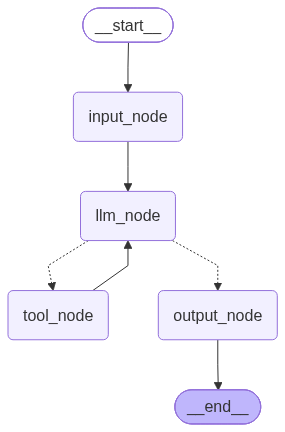

In [5]:
from IPython.display import display
display(graph)

这种方式将路由函数移动到`LLM node`,其返回值类型：`Command[Literal["tool_node", "output_node"]]`。表明该节点返回的是一个 **`Command`** 对象，且 **`goto`** 字段的值只能是：

* **`"tool_node"`**  
* 或 **`"output_node"`**

这是静态约束，不会参与运行时校验。主要作用是提升代码可读性、通过静态类型检查，同时帮助 **`LangGraph`** 更准确地推断图结构。



### 4.4.2 引入递归限制

在存在循环结构的图中，如果没有合理的停止条件，运行图可能会一直循环执行。为了避免无限循环，**`LangGraph`** 提供了**递归限制**机制，用于限制单次图运行过程中允许执行的最大 **`SuperStep`** 数量。

当超出时,**`LangGraph`** 会抛出 **`GraphRecursionError`**。

#### 4.4.2.1 步骤计数器

这个数值可以从前面的  **`RunnableConfig`** 类型 **`config`** 获取。**`LangGraph`** 运行节点时，会向节点函数注入运行时配置对象 **`config`**，用于记录本次运行的配置信息和部分运行时元数据。

```python
config["metadata"]["langgraph_step"]
```

这里的步骤编号对应图运行过程中的 **`SuperStep`**，从 `1` 开始计数。

2026-10-15 19:45:47.185 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 19:45:47.186 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-15 19:45:47.187 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 19:45:47.188 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-15 19:45:47.188 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-10-15 19:45:47.189 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


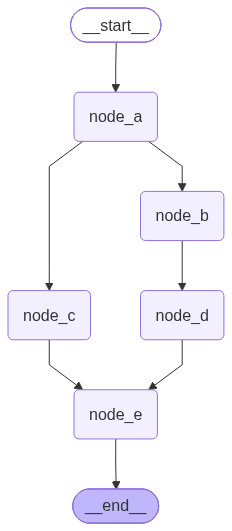

In [6]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig
from langgraph.types import Send,Command
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
# builder.add_edge(["node_c", "node_d"], "node_e")
# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

#### 4.4.2.2 配置**递归限制**
**`recursion_limit`** 表示单次图运行过程中允许执行的最大 **`SuperStep`** 数量。可以在调用运行图时通过 **`config`** 显式配置：

```python
graph.invoke(input, config={"recursion_limit": 10})
```

似乎在源码中存在多个默认值，实际最好显式设定。


#### 4.4.2.3. 优雅退出：主动方法（Proactive Approach）

**`RemainingSteps`** 是 **`LangGraph`** 提供的特殊托管值，表示**剩余可用步数**，由运行时维护。Langgraph 使用 **`RemainingSteps`** 类型字段存储，根据当前步数和 **`recursion_limit`** 计算剩余步数。

我们可以通过在状态中声明一个 **`RemainingSteps`** 类型的字段，来获取**剩余可用步数**。

这种方式是在达到递归限制之前主动处理，因此称为 **主动方法（Proactive Approach）**。这种方式在运行图内部主动处理，不会抛出异常，因此是**优雅退出**的**主动方法**。

2026-10-15 20:06:05.645 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 1, remaining_step: 9
2026-10-15 20:06:05.647 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 2, remaining_step: 8
2026-10-15 20:06:05.649 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 3, remaining_step: 7
2026-10-15 20:06:05.650 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 4, remaining_step: 6
2026-10-15 20:06:05.651 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 5, remaining_step: 5
2026-10-15 20:06:05.652 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 6, remaining_step: 4
2026-10-15 20:06:05.653 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 7, remaining_step: 3
2026-10-15 20:06:05.654 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 8, remaining_step: 2
2026-10-15 20:06:05.655 | INFO     | __main__:router:19 - 当前可用超步：2，已不足2步，终止运行图


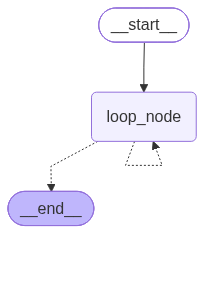

In [7]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.managed import RemainingSteps
from langchain_core.runnables.config import RunnableConfig

from loguru import logger

class OverAllState(TypedDict):
    remaining_steps: RemainingSteps

def loop_node(state: OverAllState, config: RunnableConfig) -> OverAllState:
    cur_step = config["metadata"]["langgraph_step"]
    remaining_steps = state["remaining_steps"]
    logger.info("loop_node, cur_step: {}, remaining_step: {}", cur_step, remaining_steps)

# 指定返回的值
def router(state: OverAllState) -> Literal["loop_node", END]:
    remaining_steps = state["remaining_steps"]
    if remaining_steps < 3:
        logger.info("当前可用超步：{}，已不足2步，终止运行图", remaining_steps)
        return END
    return "loop_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_conditional_edges("loop_node", router)

graph = builder.compile()
graph.invoke({}, config={"recursion_limit": 10})

from IPython.display import display
display(graph)

#### 4.4.2.4. 异常中断：被动方法（Reactive Approach）

如果图中存在循环结构，并且运行图在达到停止条件之前耗尽了允许的最大步数，**`LangGraph`** 会抛出 **`GraphRecursionError`**。

开发者可以在图外部捕获该异常，处理递归限制超限的情况。由于这种方式是在异常已经发生之后再处理，因此称为 **被动方法（`Reactive Approach`）**。

2026-10-15 20:12:29.335 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 1
2026-10-15 20:12:29.336 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 2
2026-10-15 20:12:29.337 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 3
2026-10-15 20:12:29.339 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 4
2026-10-15 20:12:29.340 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 5
2026-10-15 20:12:29.341 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 6
2026-10-15 20:12:29.342 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 7
2026-10-15 20:12:29.342 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 8
2026-10-15 20:12:29.343 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 9
2026-10-15 20:12:29.344 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 10
2026-10-15 20:12:29.345 | INFO     | __main__:<module>:24 - 超步数量达到最大限制，抛出异常: Recursion limit of 10 reached without hitting a stop condition. You can increase t

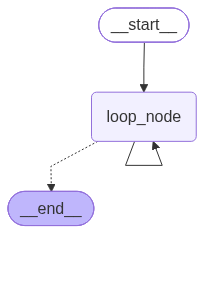

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.errors import GraphRecursionError
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def loop_node(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("loop_node, cur_step: {}", cur_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_edge("loop_node", "loop_node")

graph = builder.compile()
try:
    graph.invoke({}, config={"recursion_limit": 10})
except GraphRecursionError as e:
    logger.info("超步数量达到最大限制，抛出异常: {}", e)

from IPython.display import display
display(graph)

# 总结

### 1. Command实现与条件边实现

|            | 静态实现                               | 动态实现                   |
| ---------- | -------------------------------------- | -------------------------- |
| 路由位置   | 路由逻辑在独立的 **`router()`** 函数中 | 路由逻辑写在节点返回值中   |
| 图结构表达 | 显式声明条件边，更直观                 | 控制逻辑更内聚，代码更紧凑 |
| 适合场景   | 路由规则独立、希望图结构更清晰         | 节点执行结果直接决定下一跳 |

两种方式都能实现 **`ReAct`** 循环，本质区别不在于是否能循环，而在于：

> **路由逻辑写在哪里。**

* 基于 **`add_conditional_edges()`** 的静态实现：把控制逻辑放在图结构定义阶段；
* 基于 **`Command(goto=...)`** 的动态实现：把控制逻辑放在节点返回值中。

### 2. 主动方法和被动方法的对比

主动方法和被动方法的最大区别在于：

> **主动方法是在图内部提前处理递归限制；被动方法是在图外部捕获`递归限制异常`。**

| 方法                                 | 超限检测     | 处理方法                               | 控制流               |
| :----------------------------------- | :----------- | :------------------------------------- | :------------------- |
| 主动(借助 **`RemainingSteps`**)      | 达到限制之前 | 在图结构内部通过条件路由处理           | 图继续运行，正常结束 |
| 被动(捕获 **`GraphRecursionError`**) | 超出限制之后 | 图结构外部，通过 **`try/except`** 处理 | 图运行被异常中断     |

实际开发中，如果循环结构本身是业务逻辑的一部分，例如 **ReAct 循环、多轮反思、自我修正、工具调用重试** 等，更推荐使用主动方法，在图内部提前处理递归限制。

如果只是为了兜底防止无限循环，也可以保留被动方法，在最外层捕获 **`GraphRecursionError`**，作为最后一道防线。

# 问题

### 1. 为什么 Command[Literal["tool_node", "output_node"]] 可以限定 goto的值?

LangGraph 在定义 Command 类时，专门把泛型参数关联到了 goto 属性上。

这不是 Literal 自己决定的，也不是 Python 规定 Command[...] 必须限制 goto，而是 Command 类的作者在源码中这样设计的。

下面是简化版`Command`源码。

```python
from typing import Generic, TypeVar, Sequence, Any
from dataclasses import dataclass

N = TypeVar("N")

@dataclass
class Command(Generic[N]):
    graph: str | None = None
    update: Any | None = None
    resume: Any | None = None
    goto: N | Sequence[N] = ()
```

注意这两行：
```python
@dataclass
class Command(Generic[N]):

    goto: N | Sequence[N] = ()
```
这里其实完成了两件事：

1. Generic[N]：声明 Command 是一个带有类型参数 N 的泛型类。
2. goto: N | Sequence[N]：明确规定 goto 的类型依赖于 N。

当我们将 `N` 替换为`Literal["tool_node", "output_node"]`,实际上 goto 的类型就相应变成：

```python
goto: (
    Literal["tool_node", "output_node"]
    | Sequence[Literal["tool_node", "output_node"]]
)
```